# Cross validation
Demonstration of the benefit of using the sklearn framework

## 1. Import Packages

Below, we import both standard packages, and functions from the accompanying .py files

In [1]:
# Import standard packages

import os
import pickle
import sys

import numpy as np
import pandas as pd
from scipy import io, stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from skorch import NeuralNetRegressor
from torch import optim
from tqdm import tqdm
import spikeinterface.full as si

from Neural_Decoding.nn import FNN
from Neural_Decoding.preprocessing_funcs import LagMat, bin_spikes, bin_output

import matplotlib.pyplot as plt

/gpfs/laur/personal/gongt/micromamba/envs/decoding/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1783690690.532907 1809821 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## 2. Load Data
This notebook builds channel-wise MUA from `peaks_combined2_sorted.npy` and behavioral outputs from `texture_pca_df_preproc.pkl`.

Neural input format: `number of time bins` x `number of channels` (MUA counts).
Behavioral output format: `number of time bins` x `number of decoded features` (here PC1-PC5).

Both are binned using the same `dt`, `t_start`, and `t_end`, then rows with NaNs in behavior are removed before decoding.

In [2]:
###Load Recording###
recording_path = r"/gpfs/laur/data/0_collaboration/ceph_phys/GLC6962/GLC6962_g_g0/preprocessed"
rec = si.load(recording_path)
print(rec)

###Load Data###
peaks_path = r"/gpfs/laur/data/0_collaboration/ceph_phys/GLC6962/GLC6962_g_g0/preprocessed/thresholding_peaks_3.5/peaks_combined2_sorted.npy" 
peaks = np.load(peaks_path, allow_pickle=True) #Load peaks of all neurons
print(peaks.dtype.names)

BinaryFolderRecording: 355 channels - 30000.283521 Hz - 1 segments - 80,418,082 samples 
                       2,680.58s (44.68 minutes) - float16 dtype - 53.18 GiB
('sample_index', 'channel_index', 'amplitude', 'segment_index', 'z', 'matched_filter_score')


#### 2a. Prepare channel-wise spikes (MUA)
Map each peak to a channel, convert to seconds, and keep raw neural spike timing for overlap-first trimming.

In [16]:
print(rec.get_times()[0])

7.414796591747566


In [3]:
channel_ids = rec.get_channel_ids()
sampling_frequency = rec.get_sampling_frequency()
print(channel_ids.shape)
print(f"sampling_frequency = {sampling_frequency}")

(355,)
sampling_frequency = 30000.283520599252


In [24]:
peak_channel_index = peaks['channel_index'].astype(int)

# Important clock detail:
# - peaks['sample_index'] is frame index from recording start (0-based).
# - rec.get_times()[0] is the segment time offset.
# Absolute recording time = sample_index / fs + time_offset.
# recording_time_offset = float(rec.get_times()[0]) ### ==> but the alignment following this looks wrong? 
recording_time_offset = 0
peak_times_sec_zero = peaks['sample_index'].astype(float) / sampling_frequency
peak_times_sec = peak_times_sec_zero + recording_time_offset

# Treat each channel as one neuron (MUA): group peak times by channel
n_channels = channel_ids.shape[0]
if peak_channel_index.min() >= 0 and peak_channel_index.max() < n_channels:
    peak_row_index = peak_channel_index
    mapping_mode = "direct row index"
else:
    # Fallback: map absolute AP channel numbers (e.g. AP354) to row indices
    ap_numbers = np.array([int(str(cid).split('AP')[-1]) for cid in channel_ids], dtype=int)
    ap_to_row = {ap: i for i, ap in enumerate(ap_numbers)}
    missing = np.setdiff1d(np.unique(peak_channel_index), ap_numbers)
    if missing.size > 0:
        raise ValueError(
            f"Cannot map {missing.size} channel_index values to channel_ids. "
            f"First missing values: {missing[:10]}"
        )
    peak_row_index = np.array([ap_to_row[ch] for ch in peak_channel_index], dtype=int)
    mapping_mode = "mapped AP number -> row index"

# Keep per-channel spike times in seconds (raw, before overlap trimming)
spike_times = np.asarray(
    [peak_times_sec[peak_row_index == ch] for ch in range(n_channels)],
    dtype=object,
 )

dt = 0.2  # bin size in seconds
neural_start_raw = float(np.min(peak_times_sec))
neural_end_raw = float(np.max(peak_times_sec))

print(f"Mapping mode: {mapping_mode}")
print(f"n_channels = {n_channels}")
print(f"spike_times is an object array of length: {spike_times.shape[0]}")
print(f"rec.get_times()[0] offset: {recording_time_offset:.6f} s")
print(f"Neural spike range, zero-based: {peak_times_sec_zero.min():.3f} to {peak_times_sec_zero.max():.3f} s")
print(f"Neural spike range, offset-applied: {neural_start_raw:.3f} to {neural_end_raw:.3f} s")
print(f"Total spikes (all channels): {int(peak_times_sec.shape[0])}")

Mapping mode: direct row index
n_channels = 355
spike_times is an object array of length: 355
rec.get_times()[0] offset: 0.000000 s
Neural spike range, zero-based: 0.000 to 2680.577 s
Neural spike range, offset-applied: 0.000 to 2680.577 s
Total spikes (all channels): 1895659


#### 2b. Overlap-first binning for neural + behavioral outputs (PC1-PC5)
Neural and behavioral traces are trimmed to a common overlap window before binning, so boundaries are guaranteed identical.

In [25]:
behavior_df_path = r"/gpfs/laur/data/0_collaboration/sepia_filming/sepia_processed/ceph_analysis_dfs/GLC6633-6644-6811-6962-20260223/texture_pca_df_preproc.pkl"
metadata_df_path = r"/gpfs/laur/data/0_collaboration/sepia_filming/sepia_processed/ceph_analysis_dfs/GLC6633-6644-6811-6962-20260223/metadata_df.pkl"

texture_pca_df = pd.read_pickle(behavior_df_path)
metadata_df = pd.read_pickle(metadata_df_path)  # Loaded for reference/debug context

decode_pc_cols = [f"PC{i}" for i in range(1, 6)]
missing_pc_cols = [c for c in decode_pc_cols if c not in texture_pca_df.columns]
if len(missing_pc_cols) > 0:
    raise ValueError(f"Missing required PC columns: {missing_pc_cols}")

# Match the same animal/session style used in density_decoding_unified.py
animal = "GLC6962"
background_col = "background" if "background" in texture_pca_df.columns else None
if background_col is not None:
    beh = texture_pca_df[
        (texture_pca_df["animal"] == animal) & (texture_pca_df[background_col].astype(str).str.lower() == "eink")
    ].copy()
else:
    beh = texture_pca_df[texture_pca_df["animal"] == animal].copy()

if len(beh) == 0:
    raise ValueError("No behavioral rows found after filtering by animal/background.")

# Convert behavior time column to seconds from gate-open-style origin
if np.issubdtype(beh["time"].dtype, np.timedelta64):
    beh_t = beh["time"].dt.total_seconds().to_numpy(dtype=float)
elif np.issubdtype(beh["time"].dtype, np.datetime64):
    beh_t = (beh["time"] - beh["time"].iloc[0]).dt.total_seconds().to_numpy(dtype=float)
else:
    beh_t = beh["time"].to_numpy(dtype=float)

beh_outputs = beh[decode_pc_cols].to_numpy(dtype=float)
beh_start_raw = float(np.nanmin(beh_t))
beh_end_raw = float(np.nanmax(beh_t))

# 1) Trim BOTH streams to overlap before binning
t_start_trim = max(neural_start_raw, beh_start_raw)
t_end_trim = min(neural_end_raw, beh_end_raw)
if t_end_trim <= t_start_trim:
    raise ValueError(
        f"No overlap between neural [{neural_start_raw:.3f}, {neural_end_raw:.3f}] "
        f"and behavior [{beh_start_raw:.3f}, {beh_end_raw:.3f}] seconds."
    )

# Keep only spikes inside overlap window
peak_keep = (peak_times_sec >= t_start_trim) & (peak_times_sec < t_end_trim)
peak_times_trim = peak_times_sec[peak_keep]
peak_rows_trim = peak_row_index[peak_keep]
spike_times_trim = np.asarray(
    [peak_times_trim[peak_rows_trim == ch] for ch in range(n_channels)],
    dtype=object,
 )

# Keep only behavior rows inside overlap window
beh_keep = (beh_t >= t_start_trim) & (beh_t < t_end_trim)
beh_t_trim = beh_t[beh_keep]
beh_outputs_trim = beh_outputs[beh_keep]

# 2) Bin BOTH with the same exact boundaries
def bin_output_safe(outputs, output_times, dt_, wdw_start, wdw_end):
    edges = np.arange(wdw_start, wdw_end, dt_)
    num_bins = edges.shape[0] - 1
    output_dim = outputs.shape[1]
    out = np.full((num_bins, output_dim), np.nan, dtype=float)
    for i in range(num_bins):
        m = (output_times >= edges[i]) & (output_times < edges[i + 1])
        if np.any(m):
            out[i, :] = np.nanmean(outputs[m, :], axis=0)
    return out, edges

t_start = float(t_start_trim)
t_end = float(t_end_trim)
neural_data = bin_spikes(spike_times_trim, dt, t_start, t_end)
y_binned, t_edges = bin_output_safe(beh_outputs_trim, beh_t_trim, dt, t_start, t_end)

# Remove bins with missing behavior values, keep neural and behavior aligned
valid_mask = np.all(np.isfinite(y_binned), axis=1)
X_aligned = neural_data[valid_mask]
y_aligned = y_binned[valid_mask]
t_centers = (t_edges[:-1] + t_edges[1:]) / 2
t_centers_aligned = t_centers[valid_mask]

# Optional per-PC normalization (z-score each PC separately).
NORMALIZE_PCS_SEPARATELY = False
if NORMALIZE_PCS_SEPARATELY:
    y_mu = np.nanmean(y_aligned, axis=0, keepdims=True)
    y_sd = np.nanstd(y_aligned, axis=0, keepdims=True) + 1e-9
    y_aligned = (y_aligned - y_mu) / y_sd

print(f"Behavior rows (raw): {len(beh)}")
print(f"Raw neural range: {neural_start_raw:.3f} to {neural_end_raw:.3f} s")
print(f"Raw behavior range: {beh_start_raw:.3f} to {beh_end_raw:.3f} s")
print(f"Trimmed overlap: {t_start:.3f} to {t_end:.3f} s")
print(f"neural_data shape (all overlap bins): {neural_data.shape}")
print(f"y_binned shape (all overlap bins): {y_binned.shape}")
print(f"Valid bins: {valid_mask.sum()} / {len(valid_mask)}")
print(f"X_aligned shape: {X_aligned.shape}")
print(f"y_aligned shape: {y_aligned.shape}")
print(f"Decoded features: {decode_pc_cols}")
print(f"Per-PC normalization enabled: {NORMALIZE_PCS_SEPARATELY}")

Behavior rows (raw): 106168
Raw neural range: 0.000 to 2680.577 s
Raw behavior range: 4.471 to 2658.646 s
Trimmed overlap: 4.471 to 2658.646 s
neural_data shape (all overlap bins): (13270, 355)
y_binned shape (all overlap bins): (13270, 5)
Valid bins: 13270 / 13270
X_aligned shape: (13270, 355)
y_aligned shape: (13270, 5)
Decoded features: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']
Per-PC normalization enabled: False


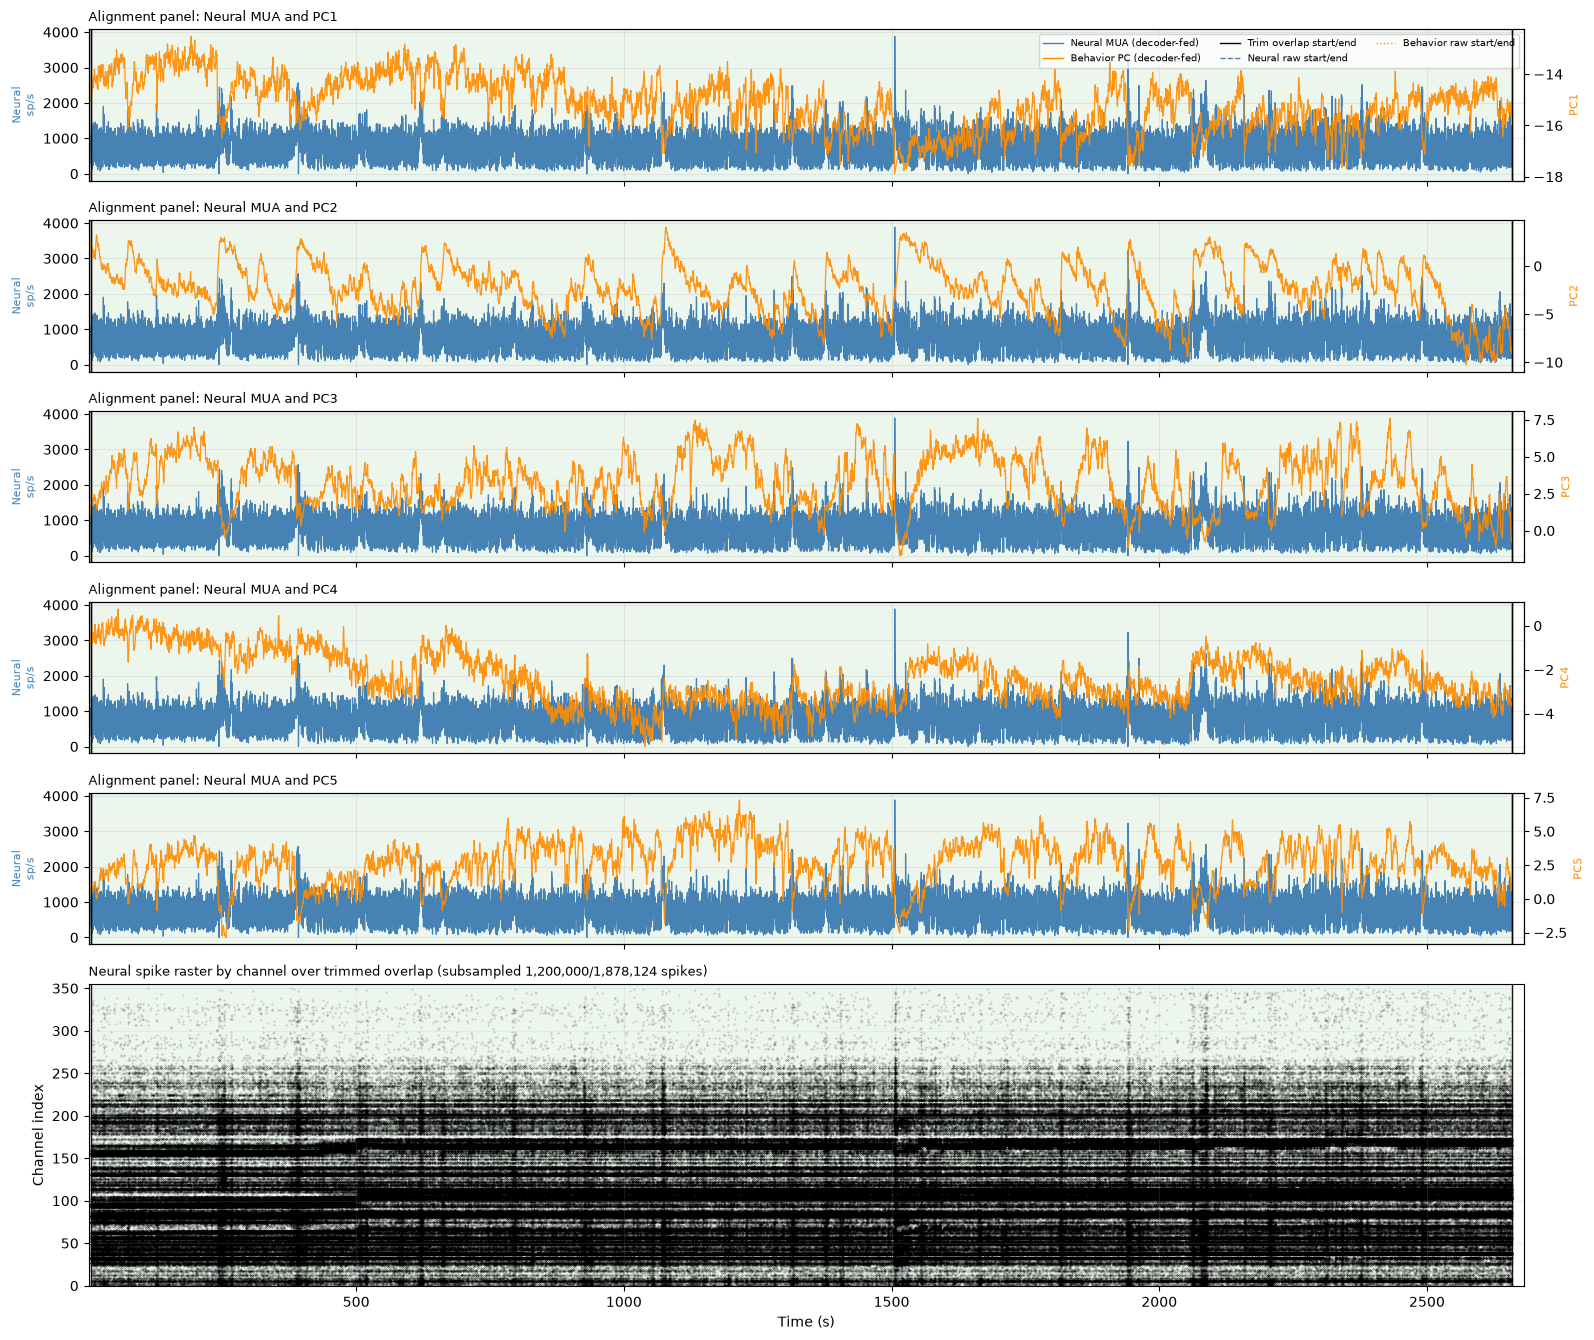

Neural NaN count: 0
Behavior NaN count: 0
Dropped bins after behavior NaN filter: 0
Per-PC normalization enabled for decoder input: False


In [26]:
# Diagnostics requested:
# (1) one panel per PC with raw decoder-fed traces (no z-scoring)
# (2) shared x-axis and bottom neural spike raster by channel

# Neural summary trace from decoder-fed neural input
neural_trace = X_aligned.sum(axis=1) / dt  # spikes/s across all channels
n_pc = len(decode_pc_cols)

fig_h = 2.0 * n_pc + 3.5
fig, axes = plt.subplots(
    n_pc + 1, 1, figsize=(16, fig_h), sharex=True,
    gridspec_kw={"height_ratios": [1] * n_pc + [2]}
)

x_full_start = min(neural_start_raw, beh_start_raw)
x_full_end = max(neural_end_raw, beh_end_raw)

for i, pc_name in enumerate(decode_pc_cols):
    ax = axes[i]
    ax_pc = ax.twinx()

    # Raw traces exactly as fed to decoder (using aligned bins only)
    ax.plot(t_centers_aligned, neural_trace, color="steelblue", lw=0.9, label="Neural MUA (sp/s)")
    ax_pc.plot(t_centers_aligned, y_aligned[:, i], color="darkorange", lw=0.9, alpha=0.9, label=f"{pc_name}")

    # Mark raw start/end and trimmed overlap boundaries
    for a in (ax, ax_pc):
        a.axvline(neural_start_raw, color="steelblue", ls="--", lw=0.8, alpha=0.7)
        a.axvline(neural_end_raw, color="steelblue", ls="--", lw=0.8, alpha=0.7)
        a.axvline(beh_start_raw, color="darkorange", ls=":", lw=0.8, alpha=0.8)
        a.axvline(beh_end_raw, color="darkorange", ls=":", lw=0.8, alpha=0.8)
        a.axvline(t_start, color="black", ls="-", lw=1.0, alpha=0.9)
        a.axvline(t_end, color="black", ls="-", lw=1.0, alpha=0.9)
    ax.axvspan(t_start, t_end, color="green", alpha=0.07, zorder=0)

    ax.set_ylabel("Neural\nsp/s", color="steelblue", fontsize=8)
    ax_pc.set_ylabel(pc_name, color="darkorange", fontsize=8)
    ax.set_title(f"Alignment panel: Neural MUA and {pc_name}", fontsize=9, loc="left")
    ax.grid(alpha=0.25)

    # Compact legend on first panel only
    if i == 0:
        l1 = ax.plot([], [], color="steelblue", lw=1.0, label="Neural MUA (decoder-fed)")[0]
        l2 = ax_pc.plot([], [], color="darkorange", lw=1.0, label="Behavior PC (decoder-fed)")[0]
        l3 = ax.plot([], [], color="black", lw=1.0, label="Trim overlap start/end")[0]
        l4 = ax.plot([], [], color="steelblue", ls="--", lw=1.0, label="Neural raw start/end")[0]
        l5 = ax.plot([], [], color="darkorange", ls=":", lw=1.0, label="Behavior raw start/end")[0]
        ax.legend(handles=[l1, l2, l3, l4, l5], fontsize=7, ncol=3, loc="upper right")

# Bottom: neural spike raster by channel (trimmed interval)
ax_raster = axes[-1]
raster_max_points = 1_200_000
if peak_times_trim.shape[0] > raster_max_points:
    rng = np.random.default_rng(0)
    keep = rng.choice(peak_times_trim.shape[0], size=raster_max_points, replace=False)
    t_r = peak_times_trim[keep]
    ch_r = peak_rows_trim[keep]
    raster_note = f"subsampled {raster_max_points:,}/{peak_times_trim.shape[0]:,} spikes"
else:
    t_r = peak_times_trim
    ch_r = peak_rows_trim
    raster_note = f"all {peak_times_trim.shape[0]:,} spikes"

ax_raster.scatter(t_r, ch_r, s=0.08, c="black", alpha=0.35, rasterized=True)
ax_raster.axvline(neural_start_raw, color="steelblue", ls="--", lw=0.8, alpha=0.7)
ax_raster.axvline(neural_end_raw, color="steelblue", ls="--", lw=0.8, alpha=0.7)
ax_raster.axvline(beh_start_raw, color="darkorange", ls=":", lw=0.8, alpha=0.8)
ax_raster.axvline(beh_end_raw, color="darkorange", ls=":", lw=0.8, alpha=0.8)
ax_raster.axvline(t_start, color="black", ls="-", lw=1.0, alpha=0.9)
ax_raster.axvline(t_end, color="black", ls="-", lw=1.0, alpha=0.9)
ax_raster.axvspan(t_start, t_end, color="green", alpha=0.07, zorder=0)
ax_raster.set_ylabel("Channel index")
ax_raster.set_xlabel("Time (s)")
ax_raster.set_title(f"Neural spike raster by channel over trimmed overlap ({raster_note})", fontsize=9, loc="left")
ax_raster.set_ylim(-1, n_channels)
ax_raster.set_xlim(x_full_start, x_full_end)
ax_raster.grid(alpha=0.15)

plt.tight_layout()
plt.show()

print(f"Neural NaN count: {int(np.isnan(X_aligned).sum())}")
print(f"Behavior NaN count: {int(np.isnan(y_aligned).sum())}")
print(f"Dropped bins after behavior NaN filter: {int((~valid_mask).sum())}")
print(f"Per-PC normalization enabled for decoder input: {NORMALIZE_PCS_SEPARATELY}")

## 3. Preprocess Data

### 3A. User Inputs
The user can define what time period to use spikes from (with respect to the output).

In [29]:
BIN_BEFORE = 6  # How many bins of neural data prior to the output are used for decoding
BIN_CURRENT = 1  # Whether to use concurrent time bin of neural data
BIN_AFTER = 6  # How many bins of neural data after the output are used for decoding

### 3B. Format Covariates

In [27]:
# Set decoding input/output (already aligned and NaN-filtered)
X = X_aligned.astype("float32")
y = y_aligned.astype("float32")

print(f"X shape (bins x channels): {X.shape}")
print(f"y shape (bins x features): {y.shape}")
print(f"Decoded features: {decode_pc_cols}")

X shape (bins x channels): (13270, 355)
y shape (bins x features): (13270, 5)
Decoded features: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']


## Save Data
Save in the same structure as `Example_format_data_hc.ipynb`: a pickle containing a 2-item list `[neural_data_matrix, output_matrix]`.

In [28]:
save_folder = r"/gpfs/laur/personal/gongt/scripts/theo_decoding/Decoding_data"
os.makedirs(save_folder, exist_ok=True)

save_path = os.path.join(save_folder, "example_data_glc6962_pc1to5.pickle")

# Same structure as Example_format_data_hc.ipynb: [neural_data, output_data]
with open(save_path, "wb") as f:
    pickle.dump([X, y], f)

# Quick verification load
with open(save_path, "rb") as f:
    neural_data_saved, output_saved = pickle.load(f)

print(f"Saved -> {save_path}")
print(f"Saved neural_data shape: {neural_data_saved.shape}")
print(f"Saved output shape: {output_saved.shape}")

Saved -> /gpfs/laur/personal/gongt/scripts/theo_decoding/Decoding_data/example_data_glc6962_pc1to5.pickle
Saved neural_data shape: (13270, 355)
Saved output shape: (13270, 5)


In [31]:
with open(save_path, "rb") as f:
    neural_data, pcs_binned = pickle.load(f, encoding="latin1")  # If using python 3

## 4. Run cross validation

#### User Options

KFold cross-validation

In [22]:
N_SPLITS = 3

In [27]:
models = {
    "WF": {
        "estimator": Pipeline(
            [
                ("scaler", StandardScaler()),
                ("lagmat", LagMat(BIN_BEFORE, BIN_CURRENT, BIN_AFTER, flat=True)),
                ("linear", LinearRegression()),
            ]
        ),
    },
    "FNN": {
        "estimator": Pipeline(
            [
                ("scaler", StandardScaler()),
                ("lagmat", LagMat(BIN_BEFORE, BIN_CURRENT, BIN_AFTER, flat=True)),
                (
                    "fnn",
                    NeuralNetRegressor(
                        module=FNN,
                        lr=0.001,
                        iterator_train__shuffle=True,
                        optimizer=optim.Adam,
                        batch_size=32,
                        module__n_targets=y.shape[1],
                        module__num_units=400,
                        module__frac_dropout=0.25,
                        module__n_layers=2,
                        max_epochs=10,
                        verbose=0,
                    ),
                ),
            ]
        ),
    },
}

for name in tqdm(models):
    model = models[name]["estimator"]

    cv_results = cross_validate(
        model,
        X,
        y,
        cv=KFold(n_splits=N_SPLITS),
        scoring="r2",
        n_jobs=1,  # parallelisation
        verbose=1,
    )

    print(f"R2s {name}: {cv_results['test_score']}")

 50%|██████████████████████████████████████████▌                                          | 1/2 [00:01<00:01,  1.57s/it]

R2s WF: [0.73822659 0.7493962  0.71846437]


[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:   42.8s finished
100%|█████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:44<00:00, 22.19s/it]

R2s FNN: [0.83662546 0.84977973 0.83463073]
